3. سوالات تکلیف

۴- ۳ ﺑﺨﺶ ﭼﻬﺎﺭﻡ: ﺳﻮﺍﻻﺕ ﺗﻜﻤﻴﻠﻲ ﻭ ﻣﻘﺎﻳﺴﻪ ﺍﻱ

3-4-1 ﻣﻘﺎﻳﺴﻪ CNN ﻭ MLP ﺭﻭی  MNIST: یک MLP ﺑﺎ ﺩﻭ ﻻﻳﻪ ﻣﺨﻔﻲ (۵۱۲ ﻭ ۲۵۶ ﻧﺮﻭﻥ) ﻭ یک  CNN ﺑﺎ ﻣﻌﻤﺎﺭﻱ ﺳﺎﺩﻩ (ﺩﻭ ﻻﻳﻪ ﻛﺎﻧﻮﻟﻮﺷﻦ + ﭘﻮﻟﻴﻨﮓ) ﺭﺍ ﺭﻭی MNIST ﺁﻣﻮﺯﺵ ﺩﻫﻴﺪ. ﺩﻗﺖ ﺁﺯﻣﻮﻥ ﻭ ﺯﻣﺎﻥ ﻫﺮ ﺩﻭﺭ ﺭﺍ ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ.

الف) ﻛﺪﺍﻡ ﻣﺪﻝ ﺳﺮﻳﻊ ﺗﺮ ﻫﻤﮕﺮﺍ ﻣﻲ ﺷﻮﺩ؟ ﻛﺪﺍﻡ ﻣﺪﻝ ﭘﺎﺭﺍﻣﺘﺮ ﻛﻤﺘﺮﻱ ﺩﺍﺭﺩ؟

ب) ﭼﻪ ﻣﺰﻳﺘﻲ ﺩﺭ CNN ﻧﺴﺒﺖ ﺑﻪ MLP ﺑﺮﺍﻱ ﺩﺍﺩﻩ ﺗﺼﻮﻳﺮﻱ ﻭﺟﻮﺩ ﺩﺍﺭﺩ ﻛﻪ ﺑﺎﻋﺚ ﻋﻤﻠﻜﺮﺩ ﺑﻬﺘﺮ ﻣﻲ ﺷﻮﺩ ؟

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision
from torchvision import transforms, datasets, models
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time
from PIL import Image
import requests
from io import BytesIO
import copy


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data, get_mnist_data_with_noise
from plotting import plot_signals
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

In [2]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist_data(batch_size=64)

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28*28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)   # flatten
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x


In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding='same')
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)   # 28 -> 14

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding='same')
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)   # 14 -> 7

        self.fc = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [5]:
def train_and_evaluate(model, model_name, train_loader, test_loader, epochs=20, lr=0.001):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_accuracies = []
    test_accuracies = []
    epoch_times = []
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    for epoch in range(epochs):
        start_time = time.time()
        # Training
        model.train()
        correct_train = 0
        total_train = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
        train_acc = 100 * correct_train / total_train
        train_accuracies.append(train_acc)

        # Evaluation
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
        test_acc = 100 * correct_test / total_test
        test_accuracies.append(test_acc)

        epoch_time = time.time() - start_time
        epoch_times.append(epoch_time)

        if (epoch+1)%5==0:print(f"{model_name} | Epoch {epoch+1:2d}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}% | Time: {epoch_time:.2f}s")

    total_time = sum(epoch_times)
    final_test_acc = test_accuracies[-1]
    return {
        'name': model_name,
        'params': num_params,
        'train_acc': train_accuracies,
        'test_acc': test_accuracies,
        'epoch_times': epoch_times,
        'total_time': total_time,
        'final_test_acc': final_test_acc
    }


In [6]:
print("\n===== Training MLP =====\n")
mlp = MLP()
mlp_results = train_and_evaluate(mlp, "MLP", train_loader, test_loader, epochs=20, lr=0.001)

print("\n===== Training CNN =====\n")
cnn = SimpleCNN()
cnn_results = train_and_evaluate(cnn, "CNN", train_loader, test_loader, epochs=20, lr=0.001)



===== Training MLP =====

MLP | Epoch  5/20 | Train Acc: 98.03% | Test Acc: 97.57% | Time: 13.53s
MLP | Epoch 10/20 | Train Acc: 98.63% | Test Acc: 98.17% | Time: 13.73s
MLP | Epoch 15/20 | Train Acc: 99.01% | Test Acc: 98.09% | Time: 14.37s
MLP | Epoch 20/20 | Train Acc: 99.14% | Test Acc: 98.07% | Time: 13.52s

===== Training CNN =====

CNN | Epoch  5/20 | Train Acc: 99.35% | Test Acc: 99.06% | Time: 13.96s
CNN | Epoch 10/20 | Train Acc: 99.75% | Test Acc: 99.01% | Time: 14.46s
CNN | Epoch 15/20 | Train Acc: 99.87% | Test Acc: 98.95% | Time: 14.04s
CNN | Epoch 20/20 | Train Acc: 99.89% | Test Acc: 99.11% | Time: 13.49s


In [7]:
print("\n===== Final Comparison =====")
print(f"{'Model':<10} {'Params':<15} {'Final Test Acc (%)':<20} {'Total Time (s)':<15}")
print("-" * 60)
print(f"{mlp_results['name']:<10} {mlp_results['params']:<15,} {mlp_results['final_test_acc']:<20.2f} {mlp_results['total_time']:<15.2f}")
print(f"{cnn_results['name']:<10} {cnn_results['params']:<15,} {cnn_results['final_test_acc']:<20.2f} {cnn_results['total_time']:<15.2f}")



===== Final Comparison =====
Model      Params          Final Test Acc (%)   Total Time (s) 
------------------------------------------------------------
MLP        535,818         98.07                273.56         
CNN        50,186          99.11                281.74         


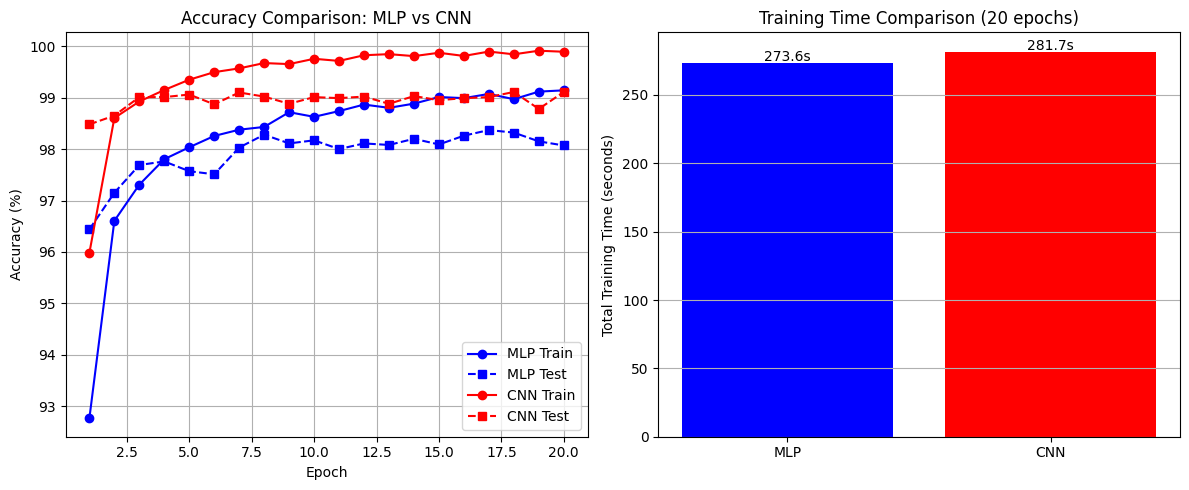

In [10]:

# Plotting training and test accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, 21), mlp_results['train_acc'], 'b-o', label='MLP Train')
plt.plot(range(1, 21), mlp_results['test_acc'], 'b--s', label='MLP Test')
plt.plot(range(1, 21), cnn_results['train_acc'], 'r-o', label='CNN Train')
plt.plot(range(1, 21), cnn_results['test_acc'], 'r--s', label='CNN Test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Comparison: MLP vs CNN')
plt.legend()
plt.grid(True)

# Plotting epoch time comparison
plt.subplot(1, 2, 2)
plt.bar(['MLP', 'CNN'], [mlp_results['total_time'], cnn_results['total_time']], color=['blue', 'red'])
plt.ylabel('Total Training Time (seconds)')
plt.title('Training Time Comparison (20 epochs)')
for i, v in enumerate([mlp_results['total_time'], cnn_results['total_time']]):
    plt.text(i, v + 1, f'{v:.1f}s', ha='center')
plt.grid(axis='y')
plt.tight_layout()
plt.savefig('mlp_cnn_comparison.png', dpi=150)
plt.show()


3-4-2 افزودن نویز به تصاویر MNIST: به تصاویر آموزش، نویز گاوسی با انحراف معیار 0.2 و 0.5 اضافه کنید. مدل CNN را از ابتدا روی داده های نویزی آموزش دهید.

الف) ﺩﻗﺖ ﻣﺪﻝ ﺩﺭ ﺣﻀﻮﺭ ﻧﻮﻳﺰ ﭼﻘﺪﺭ ﻛﺎﻫﺶ ﻣﻲ ﻳﺎﺑﺪ؟ ﺁﻳﺎ ﻻﻳﻪ ﻫﺎﻱ ﻛﺎﻧﻮﻟﻮﺷﻦ ﻣﻲ ﺗﻮﺍﻧﻨﺪ ﺗﺎ ﺣﺪﻱ ﻧﻮﻳﺰ ﺭﺍ ﻓﻴﻠﺘﺮ ﻛﻨﻨﺪ؟ (ﻧﻘﺸﻪ ﻭﻳﮋﮔﻲ ﻫﺎﻱ ﻻﻳﻪ ﺍﻭﻝ ﺭﺍ ﺑﺮﺍﻱ یک ﺗﺼﻮﻳﺮ ﻧﻮﻳﺰی ﻧﻤﺎﻳﺶ ﺩﻫﻴﺪ).

In [13]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding='same')
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding='same')
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.fc = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [17]:
def train_model(model, train_loader, test_loader, epochs=20, lr=0.001):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_accs = []
    test_accs = []
    for epoch in range(epochs):
        model.train()
        correct = 0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        train_acc = 100 * correct / total
        train_accs.append(train_acc)
        
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        test_acc = 100 * correct / total
        test_accs.append(test_acc)
        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    return train_accs, test_accs, model


In [18]:
noise_levels = [0.2, 0.5]
results = []

for noise_std in noise_levels:
    print(f"\n===== Training with noise_std = {noise_std} =====")
    if noise_std == 0.0:
        X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist_data(batch_size=64)
    else:
        train_loader, test_loader = get_mnist_data_with_noise(batch_size=64, noise_std=noise_std)
    
    model = SimpleCNN()
    start_time = time.time()
    train_accs, test_accs, trained_model = train_model(model, train_loader, test_loader, epochs=20, lr=0.001)
    total_time = time.time() - start_time
    results.append({
        'noise_std': noise_std,
        'train_accs': train_accs,
        'test_accs': test_accs,
        'final_test_acc': test_accs[-1],
        'total_time': total_time,
        'model': trained_model
    })
    print(f"Final test accuracy: {test_accs[-1]:.2f}% | Time: {total_time:.2f}s")



===== Training with noise_std = 0.2 =====
Epoch 5/20 | Train Acc: 99.29% | Test Acc: 99.02%
Epoch 10/20 | Train Acc: 99.73% | Test Acc: 99.06%
Epoch 15/20 | Train Acc: 99.80% | Test Acc: 99.12%
Epoch 20/20 | Train Acc: 99.86% | Test Acc: 99.07%
Final test accuracy: 99.07% | Time: 333.52s

===== Training with noise_std = 0.5 =====
Epoch 5/20 | Train Acc: 99.00% | Test Acc: 98.80%
Epoch 10/20 | Train Acc: 99.40% | Test Acc: 99.05%
Epoch 15/20 | Train Acc: 99.58% | Test Acc: 99.01%
Epoch 20/20 | Train Acc: 99.71% | Test Acc: 99.05%
Final test accuracy: 99.05% | Time: 328.98s


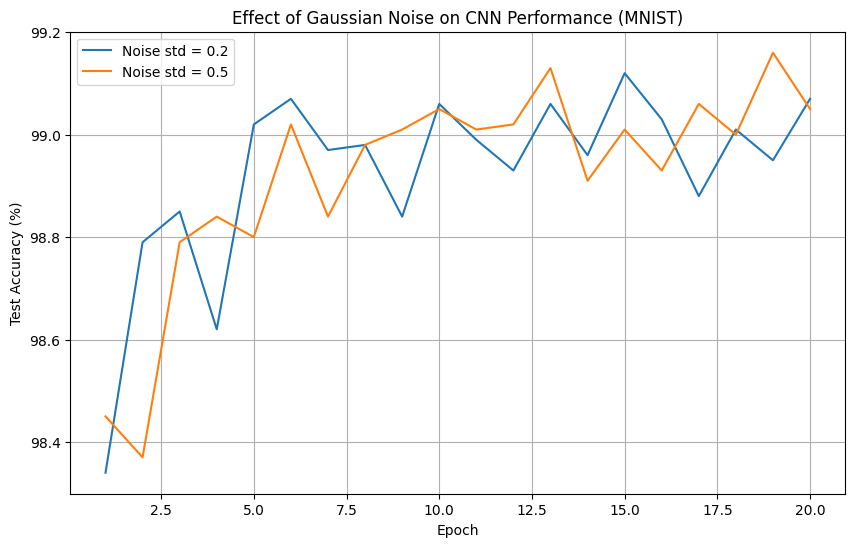

In [19]:
plt.figure(figsize=(10, 6))
for res in results:
    plt.plot(range(1, 21), res['test_accs'], label=f"Noise std = {res['noise_std']}")
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Gaussian Noise on CNN Performance (MNIST)')
plt.legend()
plt.grid(True)
plt.savefig('noise_effect_cnn.png', dpi=150)
plt.show()


In [26]:
clean_acc = 99.11
print("\n===== Accuracy Drop Summary =====")
print(f"Clean test accuracy: {clean_acc:.2f}%")
for res in results:
    if res['noise_std'] > 0:
        drop = clean_acc - res['final_test_acc']
        print(f"Noise std={res['noise_std']}: Test acc={res['final_test_acc']:.2f}% (drop={drop:.2f}%)")


===== Accuracy Drop Summary =====
Clean test accuracy: 99.11%
Noise std=0.2: Test acc=99.07% (drop=0.04%)
Noise std=0.5: Test acc=99.05% (drop=0.06%)


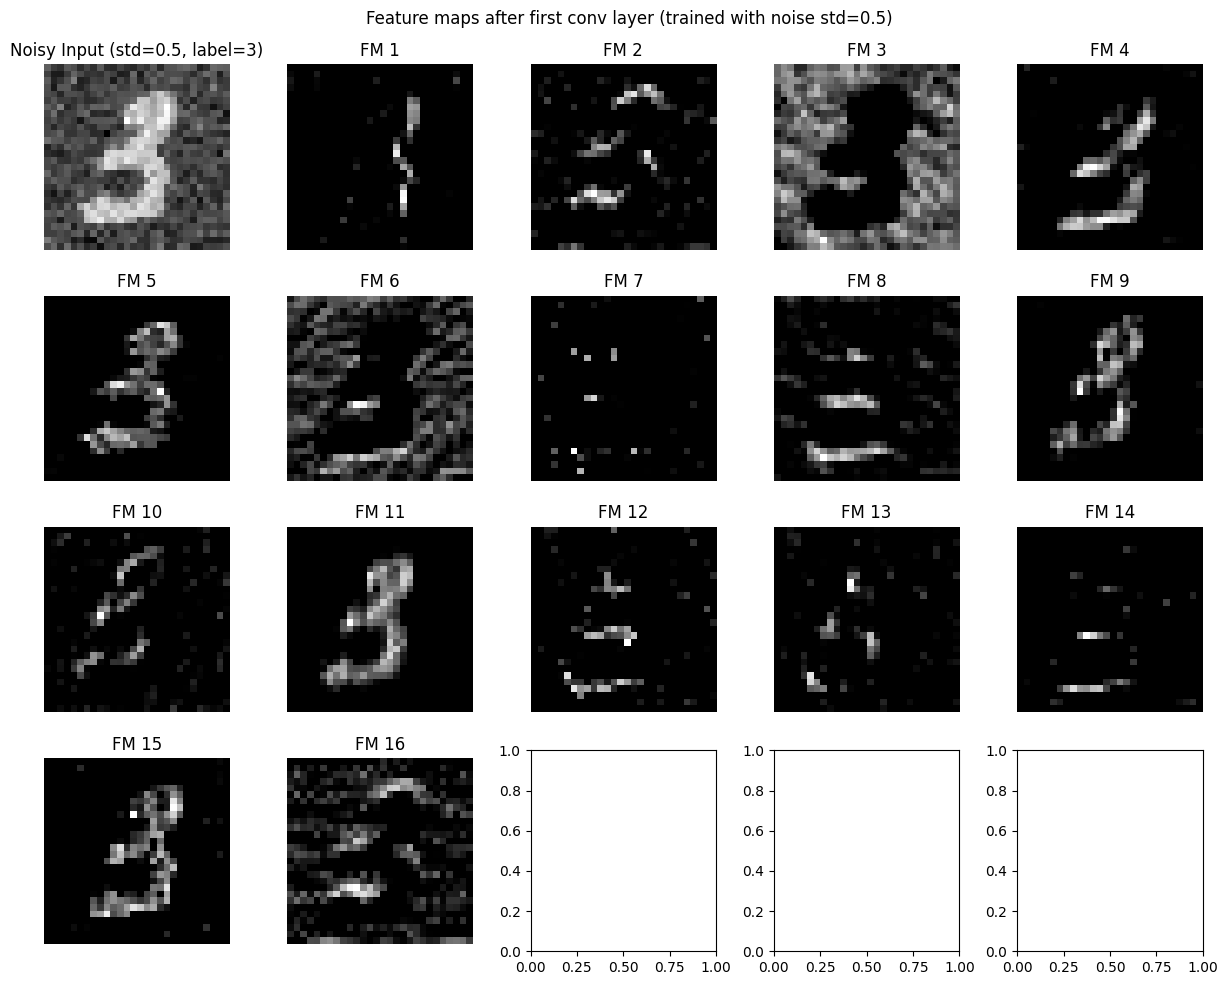

In [29]:

# ------------------------------------------------------------------
# Visualize feature maps of first conv layer on a noisy image (noise_std=0.5)
# ------------------------------------------------------------------
# Get a noisy test sample from the noisy train loader (or generate one)
noise_std_vis = 0.5
train_loader_noisy, _ = get_mnist_data_with_noise(batch_size=1, noise_std=noise_std_vis)
noisy_img, label = next(iter(train_loader_noisy))
noisy_img = noisy_img.to(device)

# Use the model trained with noise_std=0.5 to extract feature maps
model_noisy = results[1]['model']
model_noisy.eval()
with torch.no_grad():
    # Get output after first conv layer (before ReLU and pooling for better visualization)
    x = model_noisy.conv1(noisy_img)
    x = model_noisy.relu1(x)   # after ReLU
    feature_maps = x[0].cpu().numpy()  # shape: (32, 28, 28)

# Display input image and first 16 feature maps
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
axes = axes.flatten()
# Input image
img_display = noisy_img[0, 0].cpu().numpy()
axes[0].imshow(img_display, cmap='gray')
axes[0].set_title(f'Noisy Input (std={noise_std_vis}, label={label.item()})')
axes[0].axis('off')
# Feature maps
for i in range(min(16, feature_maps.shape[0])):
    fm = feature_maps[i, :, :]
    # Normalize for display
    fm_min, fm_max = fm.min(), fm.max()
    fm_norm = (fm - fm_min) / (fm_max - fm_min + 1e-8)
    axes[i+1].imshow(fm_norm, cmap='gray')
    axes[i+1].set_title(f'FM {i+1}')
    axes[i+1].axis('off')
for i in range(feature_maps.shape[0]+1, len(axes)):
    axes[i].axis('off')
plt.suptitle(f'Feature maps after first conv layer (trained with noise std={noise_std_vis})')
plt.tight_layout()
plt.savefig('feature_maps_noisy_input.png', dpi=150)
plt.show()


3-4-3 آزمایش انتقال یادگیری (Transfer Learning): یک مدل ResNet-18 از پیش آموزش دیده روی ImageNet را بارگذاری کنید. ﻻﻳﻪ ﺁﺧﺮ ﺭﺍ ﺑﺮﺍﻱ ﺩﺳﺘﻪ ﺑﻨﺪﻱ ﺍﺭﻗﺎﻡ MNIST (10 کلاس) تعویض کرده و شبکه را روی MNIST fine-tune  ﻛﻨﻴﺪ (ﻓﻘﻂ ﻻﻳﻪ ﺁﺧﺮ ﻳﺎ ﭼﻨﺪ ﻻﻳﻪ ﺁﺧر).

الف)  ﺩﻗﺖ ﻧﻬﺎﻳﻲ ﺭﺍ ﺑﺎ ﻣﺪﻝ CNN ﺍﺯ ﺻﻔﺮ ﺁﻣﻮﺯﺵ ﺩﻳﺪﻩ ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ. ﺁﻳﺎ ﺑﺎ ﻭﺟﻮﺩ ﺗﻔﺎﻭﺕ ﺯﻳﺎﺩ ﺩﺍﻣﻨﻪ ﺩﺍﺩﻩ (ﻃﺒﻴﻌﻲ ﺩﺭ ﻣﻘﺎﺑﻞ ﺩﺳﺖ ﻧﻮﺷﺘﻪ) ﺍﻧﺘﻘﺎﻝ ﻳﺎﺩﮔﻴﺮﻱ ﻣﻔﻴﺪ ﺍﺳﺖ ؟

ب) ﻭﺯﻥ ﻫﺎﻱ ﻻﻳﻪ ﺍﻭﻝ ﻛﺎﻧﻮﻟﻮﺷﻦ ResNet ﺭﺍ ﻗﺒﻞ ﻭ ﺑﻌﺪ ﺍﺯ fine-tuning ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ (ﻣﻴﺎﻧﮕﻴﻦ ﺗﻐﻴﻴﺮﺍﺕ ﺭﺍ ﻣﺤﺎﺳﺒﻪ ﻛﻨﻴﺪ).

In [30]:
# 1. Data preparation for ResNet (MNIST -> RGB 224x224)
# =====================================================
# Transform for ResNet: resize to 224, convert to 3 channels, normalize with ImageNet stats
resnet_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),  # convert 1-channel to 3-channel by repeating
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [37]:
current_dir = Path.cwd()
data_root = current_dir.parent / 'data'  # .../data
data_root = str(data_root)

# For training from scratch CNN (same as before, MNIST native size)
cnn_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Load MNIST
train_dataset = datasets.MNIST(root=data_root, train=True, download=False, transform=resnet_transform)
test_dataset = datasets.MNIST(root=data_root, train=False, download=False, transform=resnet_transform)

# For CNN from scratch (clean, no noise) we use separate loader
train_dataset_cnn = datasets.MNIST(root=data_root, train=True, download=False, transform=cnn_transform)
test_dataset_cnn = datasets.MNIST(root=data_root, train=False, download=False, transform=cnn_transform)

batch_size = 64
train_loader_resnet = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader_resnet = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=batch_size, shuffle=True)
test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=batch_size, shuffle=False)


In [38]:
def train_model(model, train_loader, test_loader, epochs=10, lr=0.001, fine_tune=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    # If fine-tuning, use smaller learning rate for backbone
    if fine_tune:
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_accs = []
    test_accs = []
    for epoch in range(epochs):
        model.train()
        correct = 0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        train_acc = 100 * correct / total
        train_accs.append(train_acc)
        
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        test_acc = 100 * correct / total
        test_accs.append(test_acc)
        print(f"Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    return model, train_accs, test_accs


In [39]:
def get_resnet_model(freeze_backbone=True):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    # Replace the final fully connected layer for 10 classes
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 10)
    if freeze_backbone:
        # Freeze all layers except the final fc
        for param in model.parameters():
            param.requires_grad = False
        for param in model.fc.parameters():
            param.requires_grad = True
    return model


In [ ]:
# Case 1: Only last layer fine-tuned
print("\n===== Transfer Learning: Only last layer fine-tuned =====")
model_resnet_last = get_resnet_model(freeze_backbone=False)
# We need to train only the new fc layer. But the input size is 224x224, so it's fine.
model_resnet_last, train_acc_last, test_acc_last = train_model(model_resnet_last, train_loader_resnet, test_loader_resnet, epochs=20, lr=0.001)
resnet_last_acc = test_acc_last[-1]
print(f"ResNet (only last layer) final test accuracy: {resnet_last_acc:.2f}%")



===== Transfer Learning: Only last layer fine-tuned =====
Epoch 1/20 | Train Acc: 90.11% | Test Acc: 94.67%
Epoch 2/20 | Train Acc: 94.88% | Test Acc: 95.88%
Epoch 3/20 | Train Acc: 95.56% | Test Acc: 95.50%
Epoch 4/20 | Train Acc: 95.91% | Test Acc: 96.23%
Epoch 5/20 | Train Acc: 96.20% | Test Acc: 96.57%
Epoch 6/20 | Train Acc: 96.46% | Test Acc: 96.19%
Epoch 7/20 | Train Acc: 96.53% | Test Acc: 96.18%
Epoch 8/20 | Train Acc: 96.62% | Test Acc: 96.59%
Epoch 9/20 | Train Acc: 96.73% | Test Acc: 96.55%
Epoch 10/20 | Train Acc: 96.88% | Test Acc: 96.80%
Epoch 11/20 | Train Acc: 96.81% | Test Acc: 96.80%
Epoch 12/20 | Train Acc: 96.95% | Test Acc: 96.82%
Epoch 13/20 | Train Acc: 97.03% | Test Acc: 96.99%
Epoch 14/20 | Train Acc: 96.97% | Test Acc: 96.89%
Epoch 15/20 | Train Acc: 97.08% | Test Acc: 96.76%
Epoch 16/20 | Train Acc: 97.06% | Test Acc: 96.92%
Epoch 17/20 | Train Acc: 97.20% | Test Acc: 97.00%
Epoch 18/20 | Train Acc: 97.16% | Test Acc: 96.75%
Epoch 19/20 | Train Acc: 97.31% 


===== Final Accuracy Comparison =====
CNN from scratch: 99.11%
ResNet-18 (only last layer): 96.85%


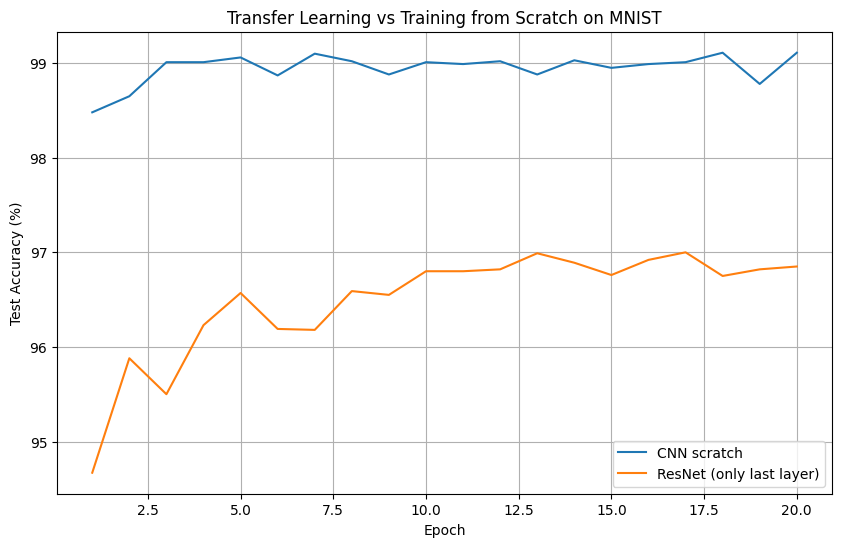

In [44]:
print("\n===== Final Accuracy Comparison =====")
print(f"CNN from scratch: 99.11%")
print(f"ResNet-18 (only last layer): {resnet_last_acc:.2f}%")
cnn_acc = cnn_results['test_acc']
# Plot convergence curves
plt.figure(figsize=(10, 6))
plt.plot(range(1, 21), cnn_acc, label='CNN scratch')
plt.plot(range(1, 21), test_acc_last, label='ResNet (only last layer)')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Transfer Learning vs Training from Scratch on MNIST')
plt.legend()
plt.grid(True)
plt.savefig('transfer_learning_comparison.png', dpi=150)
plt.show()


In [45]:
model_before = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
initial_weights = model_before.conv1.weight.data.clone().cpu().numpy()

# After fine-tuning, we have model_resnet_last which was trained
final_weights = model_resnet_last.conv1.weight.data.cpu().numpy()

# Compute mean absolute change per weight
weight_change = np.abs(final_weights - initial_weights)
mean_change = np.mean(weight_change)
std_change = np.std(weight_change)


In [ ]:

print("\n===== Weight Change Analysis (First Conv Layer) =====")
print(f"Mean absolute weight change: {mean_change:.6f}")
print(f"Std of weight change: {std_change:.6f}")



===== Weight Change Analysis (First Conv Layer) =====
Mean absolute weight change: 0.000001
Std of weight change: 0.000003


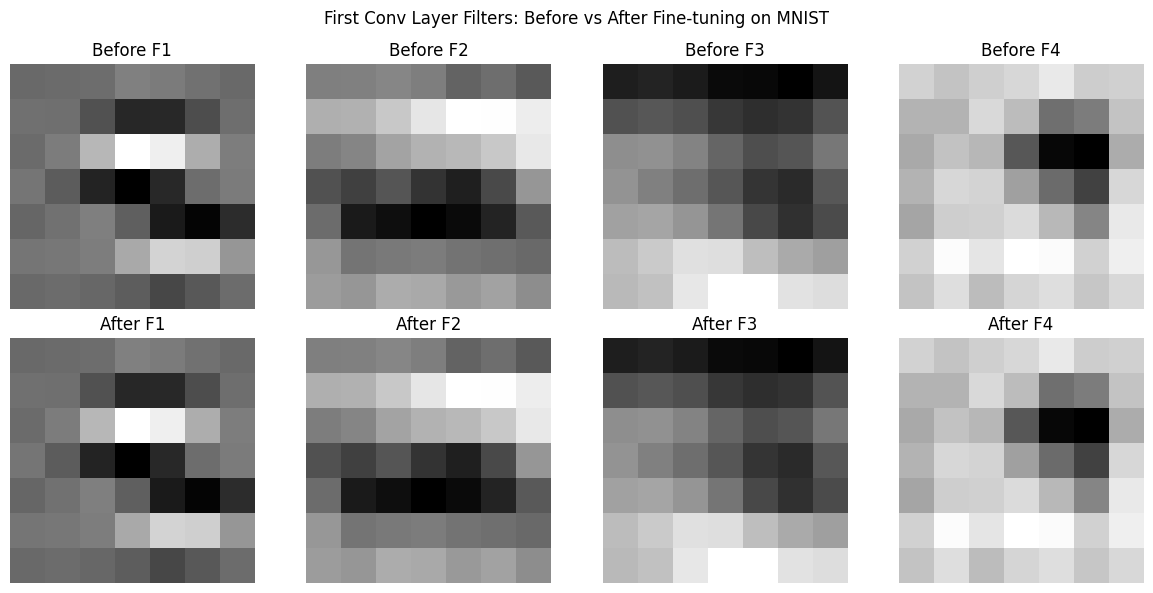

In [47]:

# Optional: Visualize a few filters before and after
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    # Before
    filt_before = initial_weights[i, 0, :, :]  # first input channel (R)
    axes[0, i].imshow(filt_before, cmap='gray')
    axes[0, i].set_title(f'Before F{i+1}')
    axes[0, i].axis('off')
    # After
    filt_after = final_weights[i, 0, :, :]
    axes[1, i].imshow(filt_after, cmap='gray')
    axes[1, i].set_title(f'After F{i+1}')
    axes[1, i].axis('off')
plt.suptitle('First Conv Layer Filters: Before vs After Fine-tuning on MNIST')
plt.tight_layout()
plt.savefig('resnet_conv1_weights_comparison.png', dpi=150)
plt.show()

3-4-4 آزمایش محو گرادیان در شبکه عمیق کانولوشنی: یک شبکه با 15 لایه کانولوشن (بدون batch normalization، بدون اتصالات باقی مانده، فعال سازی sigmoid) ﺭﻭﻱ ﺩﺍﺩﻩ ﻫﺎﻱ MNIST ﺁﻣﻮﺯﺵ دهید.

الف)  ﺁﻳﺎ ﺷﺒﻜﻪ ﻗﺎﺩﺭ ﺑﻪ ﻳﺎﺩﮔﻴﺮﻱ ﺍﺳﺖ؟ ﺧﻄﺎﻱ ﺁﻣﻮﺯﺵ ﺭﺍ ﺩﺭ ﻃﻮﻝ ﺩﻭﺭ ﻫﺎ ﺭﺳﻢ ﻛﻨﻴﺪ. ﺁﻳﺎ ﺧﻄﺎ ﺑﻪ ﻣﻘﺪﺍﺭ ﻗﺎﺑﻞ ﻗﺒﻮﻟﻲ ﻛﺎﻫﺶ ﻣﻲ ﻳﺎﺑﺪ؟ 

ب) ﻧﺮﻡ ﮔﺮﺍﺩﻳﺎﻥ ﻻﻳﻪ ﺍﻭﻝ ﻭ ﻻﻳﻪ ﺁﺧﺮ ﺭﺍ ﺩﺭ ﺍﺑﺘﺪﺍ ﻭ ﺍﻧﺘﻬﺎی ﺁﻣﻮﺯﺵ ﻣﻘﺎﻳﺴﻪ ﻛﻨﻴﺪ. ﻧﺘﻴﺠﻪ ﺭﺍ ﺑﺎ ﺣﺎﻟﺘﻲ ﻛﻪ ﺍﺯ ReLU ﻭ batch normalization  ﺍﺳﺘﻔﺎﺩﻩ ﻣﻲ ﺷﻮﺩ، ﻣﻘﺎﻳﺴﻪ ﻧﻤﺎﻳﻴﺪ.

In [49]:
class DeepCNNSigmoid(nn.Module):
    def __init__(self, num_layers=15, hidden_channels=32, kernel_size=3):
        super(DeepCNNSigmoid, self).__init__()
        layers = []
        # first layer: 1 input channel -> hidden_channels
        layers.append(nn.Conv2d(1, hidden_channels, kernel_size, stride=1, padding='same'))
        layers.append(nn.Sigmoid())
        # subsequent layers
        for _ in range(num_layers - 1):
            layers.append(nn.Conv2d(hidden_channels, hidden_channels, kernel_size, stride=1, padding='same'))
            layers.append(nn.Sigmoid())
        self.features = nn.Sequential(*layers)
        # global average pooling to reduce spatial size
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(hidden_channels, 10)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [50]:
class DeepCNNReLUBN(nn.Module):
    def __init__(self, num_layers=15, hidden_channels=32, kernel_size=3):
        super(DeepCNNReLUBN, self).__init__()
        layers = []
        layers.append(nn.Conv2d(1, hidden_channels, kernel_size, stride=1, padding='same'))
        layers.append(nn.BatchNorm2d(hidden_channels))
        layers.append(nn.ReLU())
        for _ in range(num_layers - 1):
            layers.append(nn.Conv2d(hidden_channels, hidden_channels, kernel_size, stride=1, padding='same'))
            layers.append(nn.BatchNorm2d(hidden_channels))
            layers.append(nn.ReLU())
        self.features = nn.Sequential(*layers)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(hidden_channels, 10)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [51]:
def get_gradient_norm(model, layer_idx=0):
    """layer_idx: 0 for first conv, -1 for last conv (before fc)"""
    conv_layers = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
    if not conv_layers:
        return 0.0
    target = conv_layers[layer_idx]
    if target.weight.grad is None:
        return 0.0
    return target.weight.grad.norm(2).item()


In [52]:
def train_and_monitor(model, train_loader, test_loader, epochs=20, lr=0.001, print_every=5):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_losses = []
    test_accs = []
    grad_first_norms = []
    grad_last_norms = []
    
    # Record initial gradient norms (after first backward, we'll do a dummy forward-backward)
    # Actually we need to compute gradients after first batch to get initial norms
    initial_grad_first = None
    initial_grad_last = None
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        correct_train = 0
        total_train = 0
        for batch_idx, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
            
            # Record gradient norms after first batch of first epoch (initial)
            if epoch == 0 and batch_idx == 0:
                initial_grad_first = get_gradient_norm(model, 0)
                initial_grad_last = get_gradient_norm(model, -1)
                print(f"Initial gradient norm - first conv: {initial_grad_first:.6e}, last conv: {initial_grad_last:.6e}")
        
        train_acc = 100 * correct_train / total_train
        avg_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_loss)
        
        # Evaluate on test set
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
        test_acc = 100 * correct_test / total_test
        test_accs.append(test_acc)
        
        # Record gradient norms at the end of each epoch (after training)
        grad_first_norms.append(get_gradient_norm(model, 0))
        grad_last_norms.append(get_gradient_norm(model, -1))
        
        if (epoch+1) % print_every == 0:
            print(f"Epoch {epoch+1:2d}/{epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}% | Grad first: {grad_first_norms[-1]:.2e} | Grad last: {grad_last_norms[-1]:.2e}")
    
    return {
        'train_losses': train_losses,
        'test_accs': test_accs,
        'grad_first': grad_first_norms,
        'grad_last': grad_last_norms,
        'init_grad_first': initial_grad_first,
        'init_grad_last': initial_grad_last,
        'final_grad_first': grad_first_norms[-1] if grad_first_norms else 0,
        'final_grad_last': grad_last_norms[-1] if grad_last_norms else 0,
        'final_test_acc': test_accs[-1] if test_accs else 0
    }


In [53]:
print("\n===== Experiment 1: 15-layer CNN with Sigmoid activation (no BN, no residual) =====")
model_sigmoid = DeepCNNSigmoid(num_layers=15, hidden_channels=32)
hist_sigmoid = train_and_monitor(model_sigmoid, train_loader, test_loader, epochs=20, lr=0.001, print_every=5)



===== Experiment 1: 15-layer CNN with Sigmoid activation (no BN, no residual) =====
Initial gradient norm - first conv: 1.152105e-14, last conv: 1.742466e-01
Epoch  5/20 | Loss: 2.3016 | Train Acc: 11.24% | Test Acc: 11.35% | Grad first: 1.29e-17 | Grad last: 8.11e-03
Epoch 10/20 | Loss: 2.3015 | Train Acc: 11.24% | Test Acc: 11.35% | Grad first: 1.50e-17 | Grad last: 2.82e-03
Epoch 15/20 | Loss: 2.3015 | Train Acc: 11.19% | Test Acc: 11.35% | Grad first: 2.10e-18 | Grad last: 8.16e-05
Epoch 20/20 | Loss: 2.3015 | Train Acc: 11.24% | Test Acc: 11.35% | Grad first: 4.18e-19 | Grad last: 6.96e-06


In [54]:
print("\n===== Experiment 2: 15-layer CNN with ReLU + BatchNorm =====")
model_relu_bn = DeepCNNReLUBN(num_layers=15, hidden_channels=32)
hist_relu_bn = train_and_monitor(model_relu_bn, train_loader, test_loader, epochs=20, lr=0.001, print_every=5)



===== Experiment 2: 15-layer CNN with ReLU + BatchNorm =====
Initial gradient norm - first conv: 1.213714e-01, last conv: 1.056628e-01
Epoch  5/20 | Loss: 0.0420 | Train Acc: 98.73% | Test Acc: 98.37% | Grad first: 1.33e-01 | Grad last: 9.73e-02
Epoch 10/20 | Loss: 0.0299 | Train Acc: 99.05% | Test Acc: 99.35% | Grad first: 8.31e-03 | Grad last: 8.24e-03
Epoch 15/20 | Loss: 0.0216 | Train Acc: 99.29% | Test Acc: 99.34% | Grad first: 2.38e-02 | Grad last: 1.92e-02
Epoch 20/20 | Loss: 0.0172 | Train Acc: 99.48% | Test Acc: 99.44% | Grad first: 4.28e-03 | Grad last: 3.28e-03


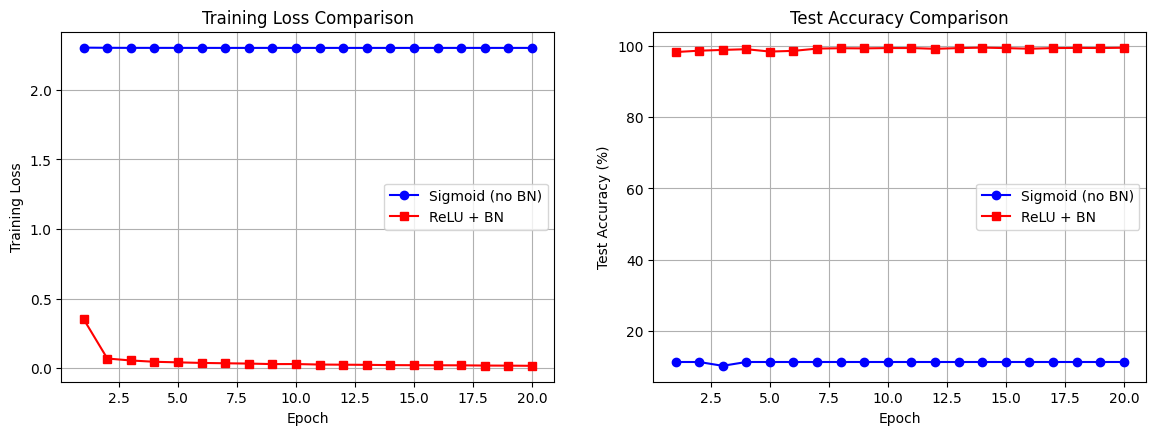

In [55]:
plt.figure(figsize=(14, 10))

# Plot training loss
plt.subplot(2, 2, 1)
plt.plot(range(1, 21), hist_sigmoid['train_losses'], 'b-o', label='Sigmoid (no BN)')
plt.plot(range(1, 21), hist_relu_bn['train_losses'], 'r-s', label='ReLU + BN')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Training Loss Comparison')
plt.legend()
plt.grid(True)

# Plot test accuracy
plt.subplot(2, 2, 2)
plt.plot(range(1, 21), hist_sigmoid['test_accs'], 'b-o', label='Sigmoid (no BN)')
plt.plot(range(1, 21), hist_relu_bn['test_accs'], 'r-s', label='ReLU + BN')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy Comparison')
plt.legend()
plt.grid(True)


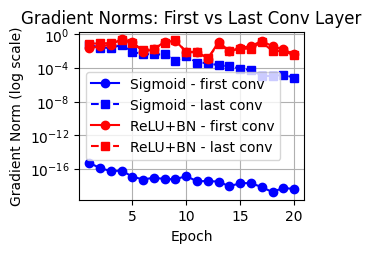

In [56]:

# Plot gradient norms for first conv layer (log scale)
plt.subplot(2, 2, 3)
plt.semilogy(range(1, 21), hist_sigmoid['grad_first'], 'b-o', label='Sigmoid - first conv')
plt.semilogy(range(1, 21), hist_sigmoid['grad_last'], 'b--s', label='Sigmoid - last conv')
plt.semilogy(range(1, 21), hist_relu_bn['grad_first'], 'r-o', label='ReLU+BN - first conv')
plt.semilogy(range(1, 21), hist_relu_bn['grad_last'], 'r--s', label='ReLU+BN - last conv')
plt.xlabel('Epoch')
plt.ylabel('Gradient Norm (log scale)')
plt.title('Gradient Norms: First vs Last Conv Layer')
plt.legend()
plt.grid(True)


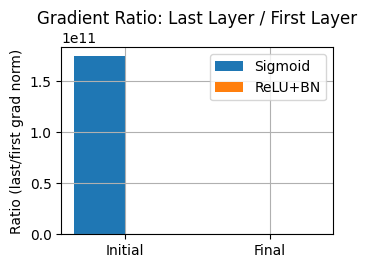

In [57]:

# Bar chart: initial vs final gradient ratio
plt.subplot(2, 2, 4)
ratios_sig = [hist_sigmoid['init_grad_last'] / max(hist_sigmoid['init_grad_first'], 1e-12),
              hist_sigmoid['final_grad_last'] / max(hist_sigmoid['final_grad_first'], 1e-12)]
ratios_relu = [hist_relu_bn['init_grad_last'] / max(hist_relu_bn['init_grad_first'], 1e-12),
               hist_relu_bn['final_grad_last'] / max(hist_relu_bn['final_grad_first'], 1e-12)]
x = np.arange(2)
width = 0.35
plt.bar(x - width/2, ratios_sig, width, label='Sigmoid')
plt.bar(x + width/2, ratios_relu, width, label='ReLU+BN')
plt.xticks(x, ['Initial', 'Final'])
plt.ylabel('Ratio (last/first grad norm)')
plt.title('Gradient Ratio: Last Layer / First Layer')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('vanishing_gradient_comparison.png', dpi=150)
plt.show()


In [58]:
print("\n===== Summary of Vanishing Gradient Experiment =====")
print(f"Sigmoid network: final test accuracy = {hist_sigmoid['final_test_acc']:.2f}%")
print(f"ReLU+BN network: final test accuracy = {hist_relu_bn['final_test_acc']:.2f}%")
print(f"\nInitial gradient norms (Sigmoid) - first: {hist_sigmoid['init_grad_first']:.2e}, last: {hist_sigmoid['init_grad_last']:.2e}, ratio: {hist_sigmoid['init_grad_last']/max(hist_sigmoid['init_grad_first'],1e-12):.2e}")
print(f"Final gradient norms (Sigmoid) - first: {hist_sigmoid['final_grad_first']:.2e}, last: {hist_sigmoid['final_grad_last']:.2e}, ratio: {hist_sigmoid['final_grad_last']/max(hist_sigmoid['final_grad_first'],1e-12):.2e}")
print(f"\nInitial gradient norms (ReLU+BN) - first: {hist_relu_bn['init_grad_first']:.2e}, last: {hist_relu_bn['init_grad_last']:.2e}, ratio: {hist_relu_bn['init_grad_last']/max(hist_relu_bn['init_grad_first'],1e-12):.2e}")
print(f"Final gradient norms (ReLU+BN) - first: {hist_relu_bn['final_grad_first']:.2e}, last: {hist_relu_bn['final_grad_last']:.2e}, ratio: {hist_relu_bn['final_grad_last']/max(hist_relu_bn['final_grad_first'],1e-12):.2e}")



===== Summary of Vanishing Gradient Experiment =====
Sigmoid network: final test accuracy = 11.35%
ReLU+BN network: final test accuracy = 99.44%

Initial gradient norms (Sigmoid) - first: 1.15e-14, last: 1.74e-01, ratio: 1.74e+11
Final gradient norms (Sigmoid) - first: 4.18e-19, last: 6.96e-06, ratio: 6.96e+06

Initial gradient norms (ReLU+BN) - first: 1.21e-01, last: 1.06e-01, ratio: 8.71e-01
Final gradient norms (ReLU+BN) - first: 4.28e-03, last: 3.28e-03, ratio: 7.68e-01
